In [1]:
from PIL import Image
import hydra
from hydra.utils import instantiate
from omegaconf import OmegaConf
import os
import torch
import numpy as np
from src.model.cnos25 import CNOS25

# Set your custom images here
reference_image = Image.open('/home/jonas/Downloads/pole.jpg')
street_img = Image.open('/home/jonas/Downloads/street.jpg')

## Setup CNOS25

In [2]:
proposal_cfg = OmegaConf.load('configs/model/proposal/yoloe.yaml')
proposal_cfg.model.text_prompts = None # prompt free
proposal_cfg.model.ultralyticsmodel.model = 'yoloe-11l-seg-pf.pt' # prompt free one

dino_cfg = OmegaConf.load('configs/model/descriptor/dinov3.yaml')
dino_cfg.cfg.cache_dir = '/tmp'
dino_cfg.cfg.cache_file = 'descriptors.pt'
dino_cfg.model.image_size = 256

local_cfg = OmegaConf.load('configs/local.yaml')
cfg = OmegaConf.merge({"model":{"descriptor":dino_cfg, "proposal":proposal_cfg}}, local_cfg)

In [3]:
proposal = instantiate(cfg.model.proposal)
descriptor = instantiate(cfg.model.descriptor)

In [4]:
cnos25 = CNOS25(proposal=proposal, descriptor=descriptor, matching_metric='max', device='cuda', lazy_load=True)

## Set Reference Image

In [5]:
reference_img_processed = cnos25.descriptor.model.process_rgb_proposals(reference_image)
reference_descriptor = cnos25.descriptor.model.chunked_fwd(reference_img_processed)[cnos25.feat_type]

cnos25.reference_descriptors = reference_descriptor.unsqueeze(0)

## Predict Test Image

In [6]:
test_proposals = cnos25.proposal_fwd_pass(street_img)
test_proposal_descriptors = cnos25.dino_fwd_pass(street_img, test_proposals)
score_per_proposal, assigned_idx_object = cnos25.classify(test_proposal_descriptors)

## Visualize Result

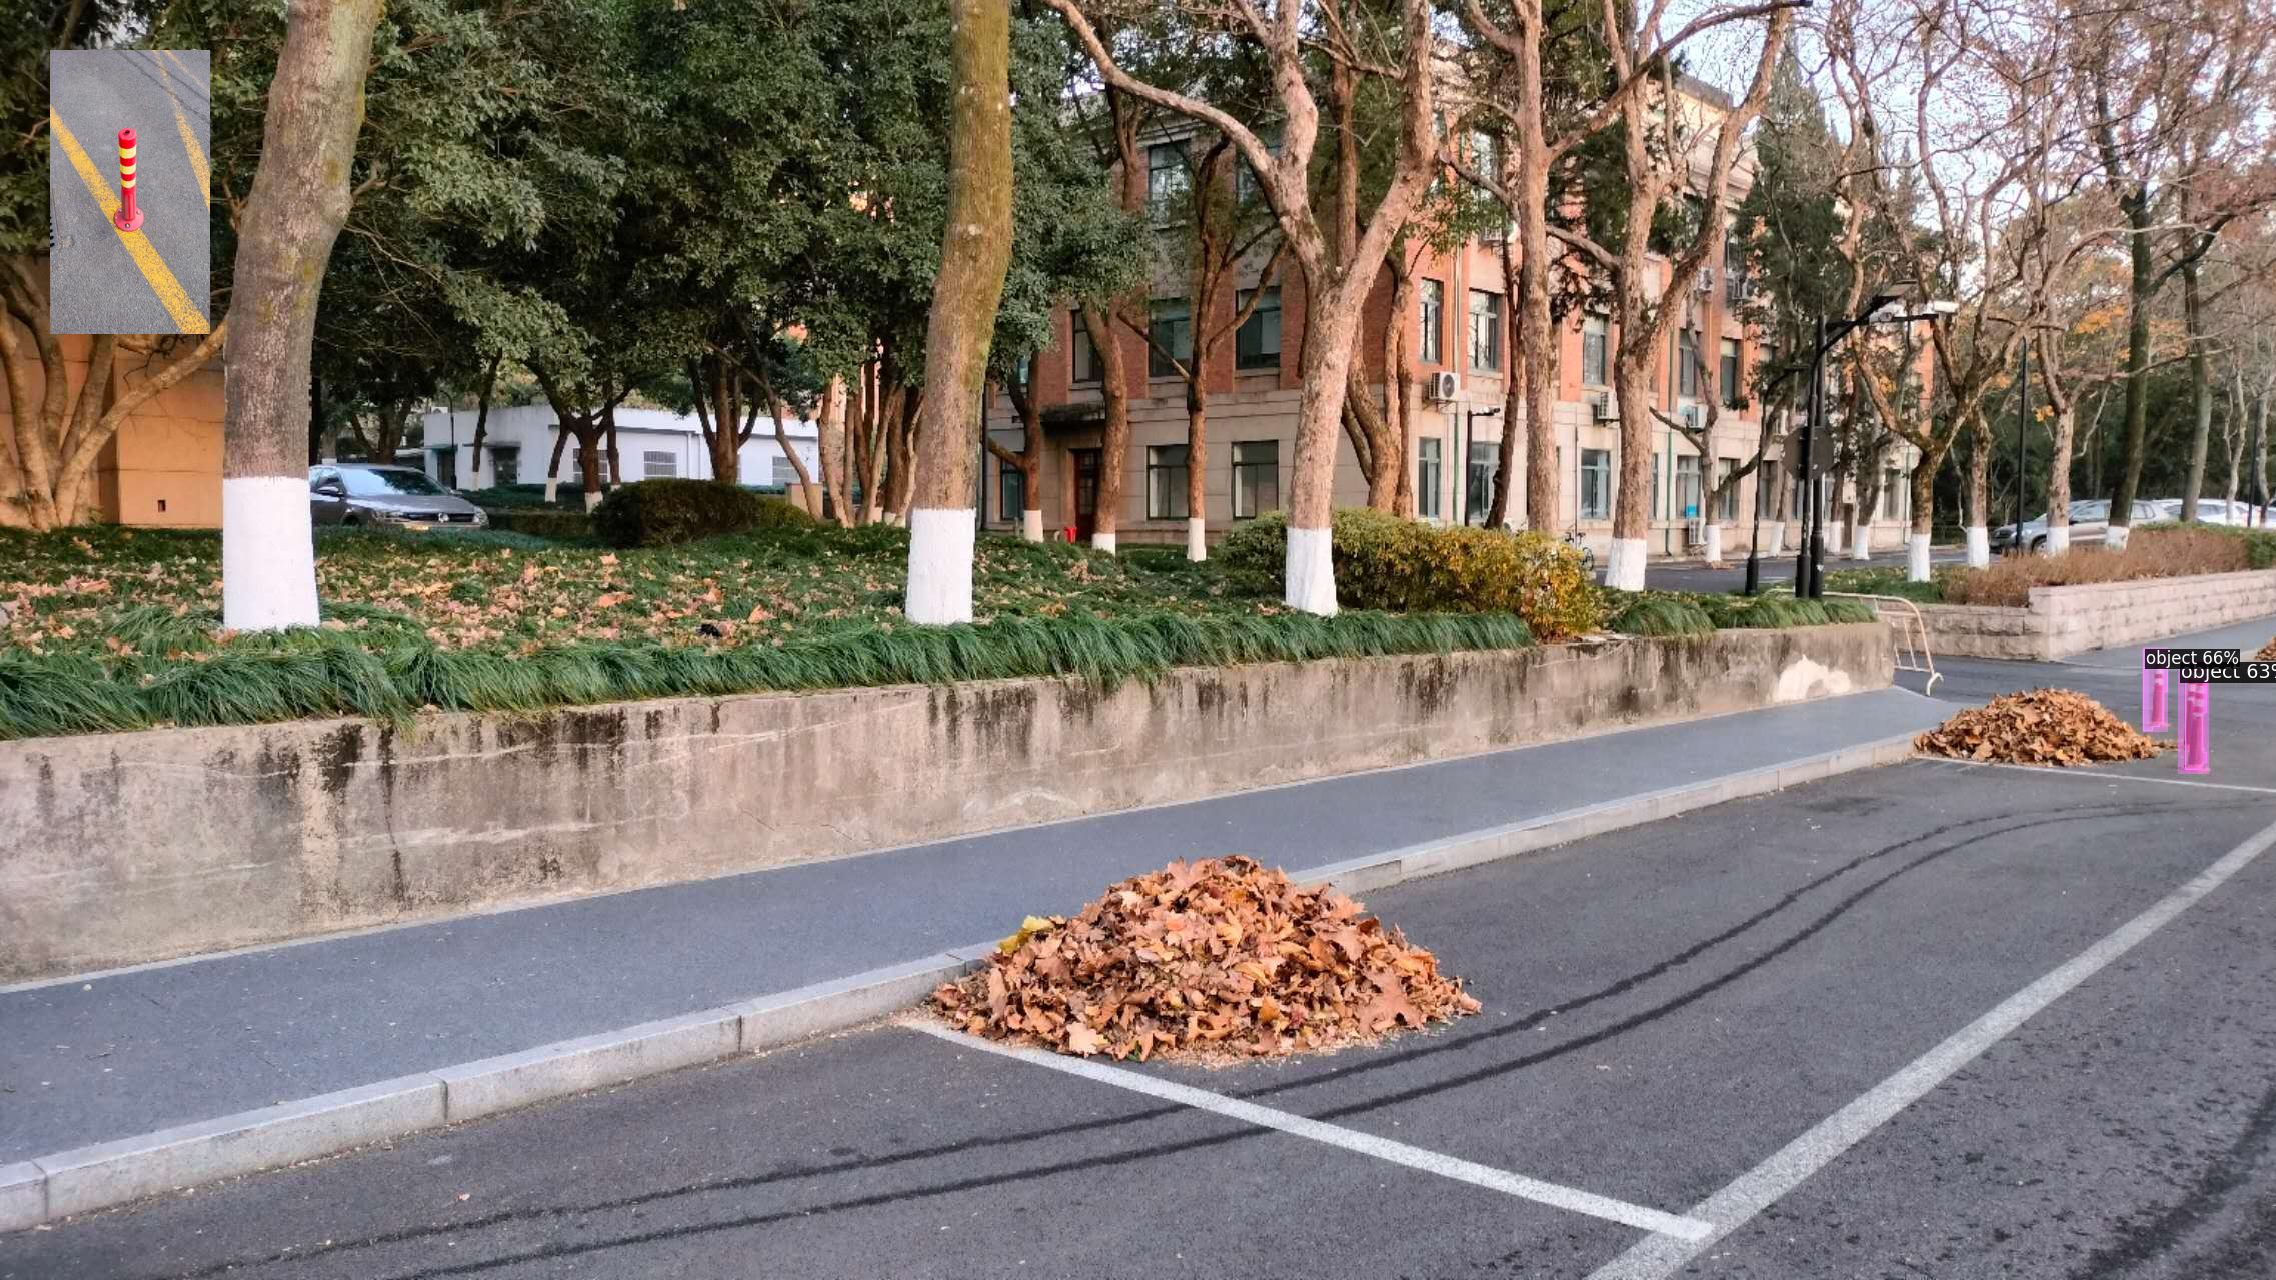

In [10]:
#!pip install git+https://github.com/facebookresearch/detectron2  # run this if you have not yet installed detectron2
from src.utils.visualization_detectron2 import CNOSVisualizer

def show_results(score_thresh=0.5):
    show = score_per_proposal.cpu() > score_thresh
    visualizer = CNOSVisualizer(["object"], img_size=np.array(street_img).shape[:2])
    visualizer.forward(rgb=np.array(street_img), 
                       masks=test_proposals.masks.cpu().numpy()[show], 
                       bboxes=test_proposals.boxes.cpu().numpy()[show], 
                       scores=score_per_proposal[show], 
                       labels=assigned_idx_object[show],
                       save_path='/tmp/demo_inference.png')
    result_viz_img = Image.open('/tmp/demo_inference.png')
    # overlay reference image on top left
    result_viz_img.paste(reference_image.resize(([s//8 for s in reference_image.size])), (50, 50)) 
    display(result_viz_img)

show_results()